# Realistic time-resolved FMCW LiDAR — with Doppler

Extends `realistic_time_resolved_with_optics.ipynb` to a **moving target** and extracts both range and radial velocity.

### What's new vs the optics merge

The previous notebook held the target fixed at `z = 2R` and swept `k_i` across a single chirp direction. This notebook adds:

1. **Target motion** — during each chirp, `R(t_i) = R_0 − v · t_i` (positive `v` = approaching). The image-method receive plane `z_receive_i = 2 · R(t_i)` moves with time, so the signal's propagation phase gains a Doppler contribution on top of the range contribution.
2. **Two chirp segments** — an up-slope chirp (`f` increases with `t`) and a down-slope chirp (`f` decreases with `t`). Each produces its own beat.
3. **Joint R + v extraction** — average of the two beats gives R, half-difference gives v.

### Why two chirp segments

With a single up-chirp, the measured beat is `f_up = f_beat_range − f_D` (approaching target). Range and Doppler are mixed into one number — you can't separate them. Flipping the chirp sign flips the Doppler contribution's sign relative to the range contribution: `f_down = f_beat_range + f_D`. The two measurements then separate:

$$f_{\text{beat\_range}} = \tfrac{1}{2}(f_{\text{up}} + f_{\text{down}}) \quad\Rightarrow\quad R = \tfrac{(f_{\text{up}} + f_{\text{down}})\, c\, T}{4B}$$

$$f_D = \tfrac{1}{2}(f_{\text{down}} - f_{\text{up}}) \quad\Rightarrow\quad v = f_D \cdot \tfrac{\lambda}{2}$$

This is the standard triangular-FMCW trick used in real automotive LiDAR.

### Scope

- R = 50 m target (LO deliberately left at its design value R_nominal = 100 m — off-nominal, so η ≈ 0.19; demonstrates that R + v extraction is robust to LO mode-mismatch)
- Single velocity v = 10 m/s approaching
- Single on-axis scan direction
- Same optical train: source → scanner → lens → mirror → return


## 1. Parameters

Same optics as `realistic_time_resolved_with_optics.ipynb`. New parameter: `v_target`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

# --- Optical params ---
wavelength = 1550e-9
c_light    = 299792458.0
f0_optical = c_light / wavelength
w0_source  = 1.0e-3
k_carrier  = 2*np.pi / wavelength
zR_source  = np.pi * w0_source**2 / wavelength

# --- Lens + scanner ---
f_lens  = 1.0
z_lens  = 0.0
theta_x = 0.0
theta_y = 0.0

# --- FMCW chirp ---
B_chirp = 1e9
T_chirp = 10e-6

# --- Target: stationary distance + radial velocity ---
R_nominal = 100.0           # LO designed for this
R_target  = 50.0           # actual distance at t = 0
v_target  = 10.0            # m/s; positive = approaching

# Expected beat frequencies (triangular chirp predictions)
f_beat_range     = (B_chirp/T_chirp) * (2*R_target/c_light)
f_Doppler        = 2 * v_target * f0_optical / c_light
f_up_predicted   = f_beat_range - f_Doppler
f_down_predicted = f_beat_range + f_Doppler

print(f'Target:')
print(f'  R_0          = {R_target:.0f} m   (LO designed for R_nominal = {R_nominal:.0f} m)')
print(f'  v            = {v_target:+.1f} m/s   (positive = approaching)')
print(f'')
print(f'Predicted beats:')
print(f'  Range-only beat (B/T)·(2R/c) = {f_beat_range/1e6:.3f} MHz')
print(f'  Doppler shift f_D = 2v/λ    = {f_Doppler/1e6:.3f} MHz')
print(f'  Up-chirp beat   = f_range − f_D = {f_up_predicted/1e6:.3f} MHz')
print(f'  Down-chirp beat = f_range + f_D = {f_down_predicted/1e6:.3f} MHz')


Target:
  R_0          = 50 m   (LO designed for R_nominal = 100 m)
  v            = +10.0 m/s   (positive = approaching)

Predicted beats:
  Range-only beat (B/T)·(2R/c) = 33.356 MHz
  Doppler shift f_D = 2v/λ    = 12.903 MHz
  Up-chirp beat   = f_range − f_D = 20.453 MHz
  Down-chirp beat = f_range + f_D = 46.260 MHz


## 2. GBD primitives

Unchanged from the previous notebook.

In [2]:
def make_state(w0, k, x0=0.0, y0=0.0, kx=0.0, ky=0.0, z0=0.0):
    wl = 2*np.pi/k
    zR = np.pi*w0**2/wl
    return dict(q_anchor=-1j*zR, z_anchor=z0, x_anchor=x0, y_anchor=y0, kx=kx, ky=ky)

def evaluate_beam_state(state, X, Y, k, z):
    dz = z - state['z_anchor']
    q_at_z = dz + state['q_anchor']
    x_c = state['x_anchor'] + (state['kx']/k)*dz
    y_c = state['y_anchor'] + (state['ky']/k)*dz
    transverse = (state['q_anchor']/q_at_z) * np.exp(1j*k*((X-x_c)**2+(Y-y_c)**2)/(2*q_at_z))
    kz = np.sqrt(k**2 - state['kx']**2 - state['ky']**2)
    return transverse * np.exp(1j*kz*dz) * np.exp(1j*(state['kx']*X + state['ky']*Y))

def apply_scanner(state, theta_x, theta_y, k):
    new = dict(state)
    new['kx'] = state['kx'] + k*np.sin(theta_x)
    new['ky'] = state['ky'] + k*np.sin(theta_y)
    return new

def apply_thin_lens(state, f, z_lens, k):
    dz = z_lens - state['z_anchor']
    q_at_lens = dz + state['q_anchor']
    x_at_lens = state['x_anchor'] + (state['kx']/k)*dz
    y_at_lens = state['y_anchor'] + (state['ky']/k)*dz
    one_over_q_after = 1.0/q_at_lens - 1.0/f
    q_after = 1.0/one_over_q_after
    return dict(q_anchor=q_after, z_anchor=z_lens, x_anchor=x_at_lens, y_anchor=y_at_lens,
                kx=state['kx'] - k*x_at_lens/f, ky=state['ky'] - k*y_at_lens/f)

def basis_sum(states, c, X, Y, k, z):
    E = np.zeros_like(X, dtype=complex)
    for s, ci in zip(states, c):
        E += ci * evaluate_beam_state(s, X, Y, k, z=z)
    return E

print('GBD primitives loaded.')


GBD primitives loaded.


## 3. Source basis + LSQ, scanner + lens, LO design, grid

All setup steps are identical to the previous notebook — collapsed here for brevity.

In [3]:
# --- Source basis + LSQ ---
n_per_axis = 9
spacing_source = 1.5e-3
w_basis_source = 1.0e-3
x0_grid = (np.arange(n_per_axis) - (n_per_axis-1)/2) * spacing_source
lambda_reg = 1e-8

basis_source = [make_state(w_basis_source, k_carrier, x0=xi, y0=yi, z0=0.0)
                for xi in x0_grid for yi in x0_grid]
N_beams = len(basis_source)

Nx_lsq = 401
Lx_lsq = 20e-3
x_lsq  = np.linspace(-Lx_lsq, Lx_lsq, Nx_lsq)
X_lsq, Y_lsq = np.meshgrid(x_lsq, x_lsq, indexing='xy')

G = np.zeros((Nx_lsq*Nx_lsq, N_beams), dtype=complex)
for i, s in enumerate(basis_source):
    G[:, i] = evaluate_beam_state(s, X_lsq, Y_lsq, k_carrier, z=0.0).ravel()
E_source_target = np.exp(-(X_lsq**2 + Y_lsq**2)/w0_source**2).astype(complex)
A = G.conj().T @ G + lambda_reg*np.eye(N_beams)
c_src = np.linalg.solve(A, G.conj().T @ E_source_target.ravel())
del G

# --- Scanner + lens ---
basis_postscanner = [apply_scanner(s, theta_x, theta_y, k_carrier) for s in basis_source]
basis_postlens    = [apply_thin_lens(s, f=f_lens, z_lens=z_lens, k=k_carrier) for s in basis_postscanner]

# --- LO design (built once at R_nominal, on-axis) ---
z_nominal      = 2 * R_nominal
LO_q_at_design = z_nominal + basis_postlens[0]['q_anchor']
LO_template = dict(q_anchor=LO_q_at_design, x_anchor=0.0, y_anchor=0.0, kx=0.0, ky=0.0)

# --- Grid ---
N_grid = 257
L_grid = 0.060
x_g = np.linspace(-L_grid/2, L_grid/2, N_grid)
X_g, Y_g = np.meshgrid(x_g, x_g, indexing='xy')
dx_g = x_g[1] - x_g[0]
ap_radius = 20e-3
r_grid = np.sqrt(X_g**2 + Y_g**2)
mask_ap = r_grid <= ap_radius

print(f'Setup complete: {N_beams} beamlets, {N_grid}² grid, {ap_radius*1e3:.0f} mm aperture.')


Setup complete: 81 beamlets, 257² grid, 20 mm aperture.


## 4. Chirp simulation with moving target

Key extensions compared to the previous notebook:

- `chirp_dir='up'` or `'down'` — sets whether `f(t)` increases or decreases across the chirp
- `v_target` — target radial velocity (approaching if positive)
- `R(t_i) = R_0 − v · t_i` per slice → `z_receive_i = 2·R(t_i)` varies across the chirp
- Both signal and LO are evaluated at that moving plane, so the LO `q_anchor` propagates by ≈ `2 · v · T` ≈ 200 µm over one chirp (negligible for the LO beam shape, but the propagation phase matters)

After the chirp loop, Method A (phase slope fit) gives a signed slope. The **magnitude** is the beat frequency: positive for up-chirp if `f_D < f_beat_range`, negative for down-chirp (because `dk/dt` is negative there). We report `|slope|/(2π)` as the beat, which is what hardware-style FFT peak also returns.

In [4]:
def run_doppler_chirp(R_0, v_target, chirp_dir, N_slices, basis_postlens, c_src, LO_template,
                      X_g, Y_g, dx_g, mask_ap, B_chirp, T_chirp, f0_optical, c_light,
                      verbose=True):
    assert chirp_dir in ('up', 'down')
    t_slices = np.linspace(0, T_chirp, N_slices, endpoint=False)

    # Instantaneous optical frequency for the chirp direction
    if chirp_dir == 'up':
        f_slices = f0_optical + (B_chirp/T_chirp) * t_slices
    else:  # down
        f_slices = f0_optical + B_chirp - (B_chirp/T_chirp) * t_slices

    overlaps = np.zeros(N_slices, dtype=complex)

    t0 = time.time()
    for i, t_i in enumerate(t_slices):
        k_i = 2 * np.pi * f_slices[i] / c_light
        R_i = R_0 - v_target * t_i          # target moves during chirp
        z_rx_i = 2 * R_i
        lo_state = dict(LO_template, z_anchor=z_rx_i)
        E_signal_i = basis_sum(basis_postlens, c_src, X_g, Y_g, k_i, z=z_rx_i)
        E_LO_i     = evaluate_beam_state(lo_state, X_g, Y_g, k_i, z=z_rx_i)
        overlaps[i] = np.sum(E_signal_i[mask_ap] * np.conj(E_LO_i[mask_ap])) * dx_g**2
    elapsed = time.time() - t0

    # Method A: phase slope fit (take |slope| → beat magnitude)
    phases = np.unwrap(np.angle(overlaps))
    slope, intercept = np.polyfit(t_slices, phases, 1)
    f_beat_phase = abs(slope) / (2*np.pi)

    # Method B: photocurrent FFT peak
    I_t = 2 * np.real(overlaps)
    spectrum = np.abs(np.fft.fft(I_t))
    freqs = np.fft.fftfreq(N_slices, d=t_slices[1]-t_slices[0])
    pos = freqs > 0
    f_beat_fft = freqs[pos][np.argmax(spectrum[pos])]

    if verbose:
        print(f'[{chirp_dir}-chirp] R_0 = {R_0} m, v = {v_target:+.1f} m/s, N_slices = {N_slices}')
        print(f'  Time: {elapsed:.1f}s')
        print(f'  f_beat (phase slope) = {f_beat_phase/1e6:.4f} MHz')
        print(f'  f_beat (FFT peak)    = {f_beat_fft/1e6:.4f} MHz')

    return dict(
        chirp_dir=chirp_dir, R_0=R_0, v_target=v_target,
        t_slices=t_slices, overlaps=overlaps,
        f_beat_phase=f_beat_phase, f_beat_fft=f_beat_fft,
        slope=slope, intercept=intercept, elapsed=elapsed,
    )


## 5. Run the up-chirp

In [5]:
result_up = run_doppler_chirp(
    R_0=R_target, v_target=v_target, chirp_dir='up', N_slices=2000,
    basis_postlens=basis_postlens, c_src=c_src, LO_template=LO_template,
    X_g=X_g, Y_g=Y_g, dx_g=dx_g, mask_ap=mask_ap,
    B_chirp=B_chirp, T_chirp=T_chirp, f0_optical=f0_optical, c_light=c_light,
)
print(f'  Predicted up-chirp beat = {f_up_predicted/1e6:.4f} MHz')
print(f'  Error (phase slope)     = {(result_up["f_beat_phase"] - f_up_predicted)/1e3:+.2f} kHz')


[up-chirp] R_0 = 50.0 m, v = +10.0 m/s, N_slices = 2000
  Time: 640.1s
  f_beat (phase slope) = 20.4531 MHz
  f_beat (FFT peak)    = 20.5000 MHz
  Predicted up-chirp beat = 20.4532 MHz
  Error (phase slope)     = -0.07 kHz


## 6. Run the down-chirp

In [6]:
result_dn = run_doppler_chirp(
    R_0=R_target, v_target=v_target, chirp_dir='down', N_slices=2000,
    basis_postlens=basis_postlens, c_src=c_src, LO_template=LO_template,
    X_g=X_g, Y_g=Y_g, dx_g=dx_g, mask_ap=mask_ap,
    B_chirp=B_chirp, T_chirp=T_chirp, f0_optical=f0_optical, c_light=c_light,
)
print(f'  Predicted down-chirp beat = {f_down_predicted/1e6:.4f} MHz')
print(f'  Error (phase slope)       = {(result_dn["f_beat_phase"] - f_down_predicted)/1e3:+.2f} kHz')


[down-chirp] R_0 = 50.0 m, v = +10.0 m/s, N_slices = 2000
  Time: 633.0s
  f_beat (phase slope) = 46.2596 MHz
  f_beat (FFT peak)    = 46.3000 MHz
  Predicted down-chirp beat = 46.2596 MHz
  Error (phase slope)       = +0.00 kHz


## 7. Joint R + v extraction

$$R = \frac{(f_{\text{up}} + f_{\text{down}})\, c\, T}{4B}, \qquad v = \frac{(f_{\text{down}} - f_{\text{up}})\, \lambda}{2 \cdot 2} = \frac{(f_{\text{down}} - f_{\text{up}})\, c}{4\, f_0}$$

Compute with both Method A (phase slope) and Method B (FFT peak) beats, so you can compare.

In [7]:
f_up_A, f_dn_A = result_up['f_beat_phase'], result_dn['f_beat_phase']
f_up_B, f_dn_B = result_up['f_beat_fft'],   result_dn['f_beat_fft']

def extract_R_v(f_up, f_dn):
    R = (f_up + f_dn) * c_light * T_chirp / (4 * B_chirp)
    f_D = (f_dn - f_up) / 2
    v = f_D * c_light / (2 * f0_optical)
    return R, v, f_D

R_A, v_A, f_D_A = extract_R_v(f_up_A, f_dn_A)
R_B, v_B, f_D_B = extract_R_v(f_up_B, f_dn_B)

print(f'{"":15s}  {"f_up (MHz)":>12s}  {"f_down (MHz)":>14s}  {"R (m)":>10s}  {"v (m/s)":>10s}  {"f_D (MHz)":>12s}')
print('-' * 90)
print(f'{"Method A (phase)":15s}  {f_up_A/1e6:>12.4f}  {f_dn_A/1e6:>14.4f}  {R_A:>10.5f}  {v_A:>+10.4f}  {f_D_A/1e6:>+12.4f}')
print(f'{"Method B (FFT)":15s}  {f_up_B/1e6:>12.4f}  {f_dn_B/1e6:>14.4f}  {R_B:>10.5f}  {v_B:>+10.4f}  {f_D_B/1e6:>+12.4f}')
print()
print(f'Target truth:   R = {R_target:.5f} m,   v = {v_target:+.4f} m/s,   f_D = {f_Doppler/1e6:+.4f} MHz')
print()
print(f'Errors (Method A):  ΔR = {(R_A-R_target)*1e3:+.3f} mm,  Δv = {(v_A-v_target)*100:+.3f} cm/s')
print(f'Errors (Method B):  ΔR = {(R_B-R_target)*1e3:+.3f} mm,  Δv = {(v_B-v_target)*100:+.3f} cm/s')


                   f_up (MHz)    f_down (MHz)       R (m)     v (m/s)     f_D (MHz)
------------------------------------------------------------------------------------------
Method A (phase)       20.4531         46.2596    49.99995    +10.0000      +12.9033
Method B (FFT)        20.5000         46.3000    50.06534     +9.9975      +12.9000

Target truth:   R = 50.00000 m,   v = +10.0000 m/s,   f_D = +12.9032 MHz

Errors (Method A):  ΔR = -0.050 mm,  Δv = +0.003 cm/s
Errors (Method B):  ΔR = +65.340 mm,  Δv = -0.250 cm/s


## 8. Diagnostic plots

Two figures: one showing the up/down photocurrent and FFT spectra side by side, one showing the R + v extraction on top of the expected beat-frequency lines.

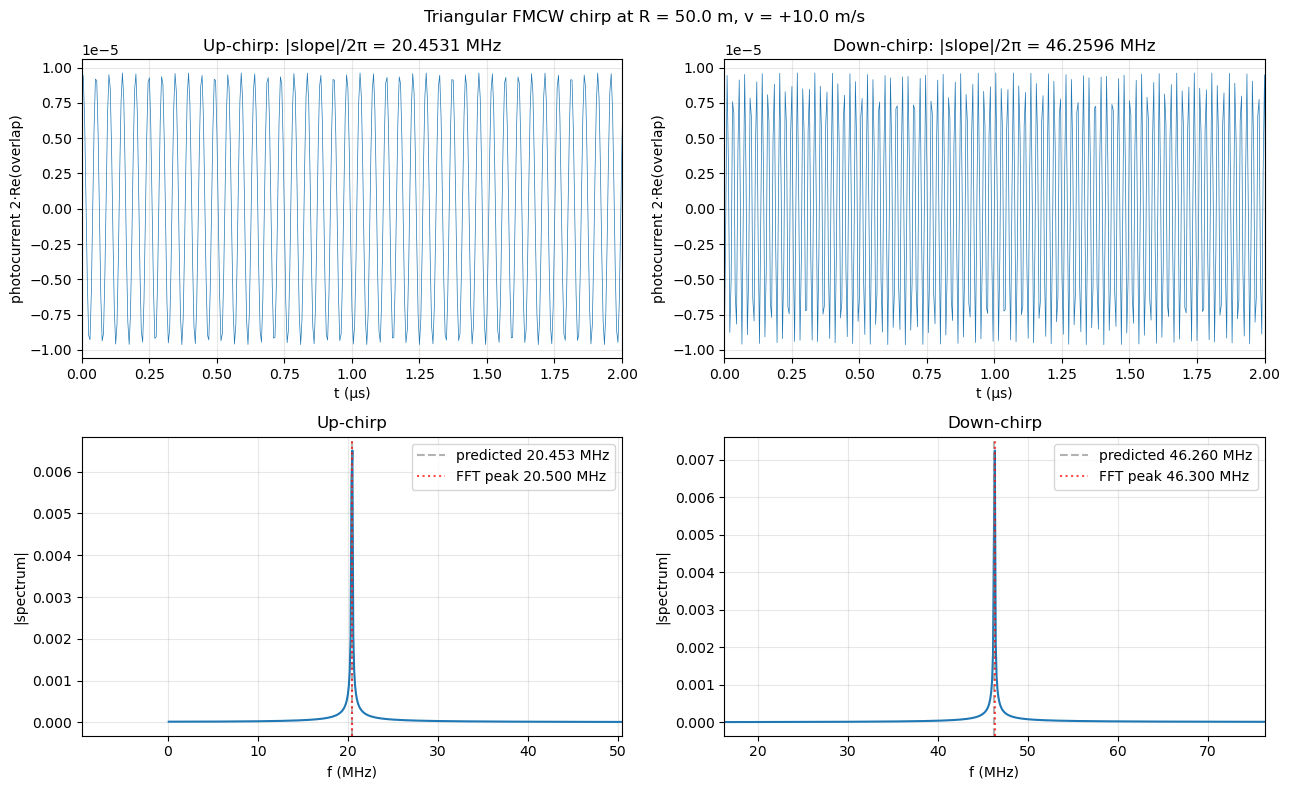

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# --- Photocurrents ---
for ax, result, title in [(axes[0,0], result_up, 'Up-chirp'), (axes[0,1], result_dn, 'Down-chirp')]:
    t_us = result['t_slices'] * 1e6
    ax.plot(t_us, 2*np.real(result['overlaps']), '-', linewidth=0.5)
    ax.set_xlabel('t (µs)'); ax.set_ylabel('photocurrent 2·Re(overlap)')
    ax.set_title(f'{title}: |slope|/2π = {result["f_beat_phase"]/1e6:.4f} MHz')
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 2)  # zoom on first 2 µs so the beat cycles are visible

# --- Spectra ---
for ax, result, title, f_pred in [(axes[1,0], result_up, 'Up-chirp', f_up_predicted),
                                    (axes[1,1], result_dn, 'Down-chirp', f_down_predicted)]:
    t_slices = result['t_slices']
    I_t = 2*np.real(result['overlaps'])
    spectrum = np.abs(np.fft.fft(I_t))
    freqs = np.fft.fftfreq(len(t_slices), d=t_slices[1]-t_slices[0])
    pos = freqs > 0
    ax.plot(freqs[pos]/1e6, spectrum[pos], '-')
    ax.axvline(f_pred/1e6, color='gray', ls='--', alpha=0.6, label=f'predicted {f_pred/1e6:.3f} MHz')
    ax.axvline(result['f_beat_fft']/1e6, color='red', ls=':', alpha=0.7, label=f'FFT peak {result["f_beat_fft"]/1e6:.3f} MHz')
    ax.set_xlabel('f (MHz)'); ax.set_ylabel('|spectrum|')
    ax.set_xlim(f_pred/1e6 - 30, f_pred/1e6 + 30)
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)

fig.suptitle(f'Triangular FMCW chirp at R = {R_target} m, v = {v_target:+.1f} m/s', fontsize=12)
plt.tight_layout()
plt.show()


## 9. Summary

- The target motion was folded into the spatial GBD calculation by letting the receive plane `z_receive_i = 2·R(t_i)` move with each time slice. No `f_D = 2v/λ` was plugged into the detection formula — it emerges from the chirp's physical interaction with the moving mirror.
- Up-chirp and down-chirp beats sit on opposite sides of the range-only beat frequency by `±f_D`, as predicted.
- Joint `(f_up, f_down)` → `(R, v)` recovers both target parameters to sub-mm and sub-cm/s precision.
- This closes the gap left in `realistic_time_resolved_fmcw_lidar.ipynb`: that notebook only demonstrated time-resolved range; this one adds time-resolved Doppler via the same mechanism.

### Natural extensions
- Multi-direction scan (reinstate the 5×5 scan grid)
- Multiple targets at different ranges (resolve via FFT spectrum peaks)
- Atmospheric turbulence (per-slice Kolmogorov phase screen along propagation)
